# Vivienda entre medianeras. Piso 1 existente

Levantamiento 2D de la planta existente (baño, cocina, sala, dormitorio, mas escalera y corredor) reconstruido desde el plano `PLANTA - PISO 1 - EXISTENTE`, esc. 1/25, de la carpeta de venta.

**Sistema de coordenadas**: 1 unidad = 1 metro. `X = 0` en el limite de propiedad izquierdo sobre la fachada, `Y = 0` sobre la fachada, `+X` al este, `+Y` al fondo del lote, `+Z` hacia arriba. Todos los muros son ortogonales.

**Linderos**

Todo el contorno del territorio tiene vecino y los muros de lindero son **medianeros**: muro compartido, nuestro muro ocupa todo el espesor dentro del lote y el vecino aporta el otro tanto.

- La Z deja dos muescas que son **territorio del vecino**: `X 6,64-8,62 / Y 0,00-3,37` (vecino este) y `X 0,00-4,22 / Y 3,52-7,64` (vecino oeste).
- Al **sur** corre un **pasillo compartido de 1,50 m** delante de la fachada, fuera del lote. Lo **parte un muro** alineado con el tabique del baño/cocina (`X 2,37-2,52`): a la **izquierda** (oeste) queda territorio del vecino y a la **derecha** (este) queda el pasillo.
- **Excepcion**: el muro del **fondo del dormitorio (M5, Y = 7,64)** no es medianero, es muro propio de cierre, pero **si hay vecino** del otro lado. Es el unico lindero que no es medianera.
- **Muros compartidos**: `M3`, la medianera frontal del bloque de fondo, se dibuja con el espesor completo `0,30`: `0,15` propios adentro del lote mas `0,15` del vecino, con la linea de propiedad en el medio. `M7`, la medianera trasera del bloque delantero, va completa adentro del lote (`3,22-3,52`): el muro crece hacia la sala y la cocina y queda al ras de la barra izquierda del paso.
- **Columna izquierda**: `0,15` de fachada + `0,96` de baño + `0,10` de tabique humedo + `2,01` de cocina + `0,30` de M7 = `3,52`, el ancho del bloque delantero. El tabique entre baño y cocina es de `0,10`, medido y dibujado a esa escala.

**Paso al dormitorio**

La sala y el dormitorio se vinculan por un paso libre de `1,17 m` enmarcado por **dos barras de `0,30` de espesor**, no de `0,15`: la izquierda de `0,38` contra la cara interior de `M6` y la derecha de `0,25`.

El **frente del dormitorio arranca en la cara este de la barra derecha** (`X 6,17`) y corre hasta la cara interior de `M4` (`X 8,47`): son los `2,30` del resto derecho, de los cuales `0,17` es el arranque del muro sobre la cara interior de `M2` y `2,13` el frente propio de `M3`.

El recuadro del dormitorio entre caras interiores cierra en `4,10 = 0,38 + 1,17 + 0,25 + 2,30`, medido desde la cara interior de `M6`, y la cadena del bloque delantero tambien: `4,22 + 0,15 + 0,38 + 1,17 + 0,25 + 0,47 = 6,64`.

**Criterio de medicion**

- El poligono de limites de propiedad es la cara exterior de nuestros muros. Las caras interiores **no se escriben a mano**: se derivan por offset hacia adentro del lote, con inglete en las esquinas.
- Espesores medidos dentro del lote, tal cual el plano: fachada `0.15`, medianeras laterales del bloque delantero `0.30`, medianeras del bloque de fondo `0.15`, tabiques `0.15` y tabique humedo `0.10`.
- Los locales se miden **siempre entre caras interiores** (superficie util). La superficie cubierta a caras exteriores se informa aparte y no se mezcla con la util.
- Los vanos se definen relativos al muro: `(id_muro, distancia desde el origen de la cara de referencia, ancho, antepecho, altura libre)`. Los vanos de fachada solo van sobre `Y = 0`; las medianeras no llevan vanos.
- El pasillo compartido, el territorio del vecino y el muro divisorio quedan **fuera del lote**: no suman superficie cubierta ni util.

**Cadenas de cotas del plano que se verifican en la celda de constantes**: `6.64`, `8.47`, `4.40`, `3.52`, `7.64`, `3.82`, `1.80` y `4.10`.


In [1]:
# 1 y 2. librerias, configuracion y constantes del levantamiento
from dataclasses import dataclass
import math

import matplotlib.pyplot as plt
from matplotlib.patches import Arc, Circle, Ellipse, Polygon, Rectangle

# cotas maestras leidas del plano (esc 1/25) y confirmadas
X_LIMITE_IZQ_M = 0.00
X_BLOQUE_DELANTERO_DER_M = 6.64
X_BLOQUE_FONDO_IZQ_M = 4.22
X_BLOQUE_FONDO_DER_M = 8.62
Y_FACHADA_M = 0.00
Y_BLOQUE_FONDO_FRENTE_M = 3.37
Y_BLOQUE_DELANTERO_FONDO_M = 3.52
Y_FONDO_M = 7.64

# espesores medidos hacia adentro del lote, tal cual el plano
ESP_FACHADA_M = 0.15
ESP_MEDIANERA_030_M = 0.30
ESP_MEDIANERA_015_M = 0.15
ESP_TABIQUE_M = 0.15
ESP_TABIQUE_HUMEDO_M = 0.10

# columna izquierda del bloque delantero, de la fachada hacia el fondo: el tabique humedo de
# 0.10 y M7 de 0.30 entran en los 3.52 del bloque, sin tocar las medidas de bano y cocina
CADENA_COLUMNA_IZQ_M = [ESP_FACHADA_M, 0.96, ESP_TABIQUE_HUMEDO_M, 2.01, ESP_MEDIANERA_030_M]
Y_INTERIOR_FACHADA_M = Y_FACHADA_M + ESP_FACHADA_M
Y_BANO_FONDO_M = Y_INTERIOR_FACHADA_M + 0.96
Y_TABIQUE_BANO_FONDO_M = Y_BANO_FONDO_M + ESP_TABIQUE_HUMEDO_M
Y_COCINA_FONDO_M = Y_TABIQUE_BANO_FONDO_M + 2.01

if abs(sum(CADENA_COLUMNA_IZQ_M) - (Y_BLOQUE_DELANTERO_FONDO_M - Y_FACHADA_M)) > 1e-9:
    raise ValueError('la columna izquierda no cierra el bloque delantero en 3.52')
if abs(Y_COCINA_FONDO_M - (Y_BLOQUE_DELANTERO_FONDO_M - ESP_MEDIANERA_030_M)) > 1e-9:
    raise ValueError('la cocina no termina en la cara interior de M7')

# nivel dibujado y datos generales
NIVEL = 'piso 1'
ALTURA_LOCAL_M = 2.60

# pasillo compartido delante de la fachada: 1,50 m fuera del lote, partido por un muro
# que continua el tabique T2 del bano-cocina
ANCHO_PASILLO_COMPARTIDO_M = 1.50
CORREDOR_FONDO_M = ANCHO_PASILLO_COMPARTIDO_M
Y_PASILLO_FONDO_M = Y_FACHADA_M - ANCHO_PASILLO_COMPARTIDO_M
X_MURO_PASILLO_IZQ_M = 2.37
X_MURO_PASILLO_DER_M = 2.52
ESP_MURO_PASILLO_M = ESP_TABIQUE_M

# recuadro del dormitorio entre caras interiores, medido desde la cara interior de M6:
# 0.38 de barra izquierda + 1.17 de paso + 0.25 de barra derecha + 2.30 de muro = 4.10
ESP_BARRA_PASO_M = 0.30
BARRA_PASO_IZQ_LARGO_M = 0.38
PASO_LIBRE_M = 1.17
BARRA_PASO_DER_LARGO_M = 0.25
RESTO_DERECHO_DORMITORIO_M = 2.30
# la cara norte de las barras coincide con el frente del dormitorio; el espesor crece hacia la
# sala, asi la profundidad util del dormitorio (3.97) no cambia
Y_BARRA_PASO_FONDO_M = Y_BLOQUE_DELANTERO_FONDO_M
Y_BARRA_PASO_FRENTE_M = Y_BLOQUE_DELANTERO_FONDO_M - ESP_BARRA_PASO_M
X_BARRA_PASO_IZQ_DESDE_M = X_BLOQUE_FONDO_IZQ_M + ESP_MEDIANERA_015_M
X_BARRA_PASO_IZQ_HASTA_M = X_BARRA_PASO_IZQ_DESDE_M + BARRA_PASO_IZQ_LARGO_M
# el paso se mide entre las dos barras y no absorbe diferencias: asi el recuadro del
# dormitorio conserva sus 4.10 con los valores del plano
X_BARRA_PASO_DER_DESDE_M = X_BARRA_PASO_IZQ_HASTA_M + PASO_LIBRE_M
X_BARRA_PASO_DER_HASTA_M = X_BARRA_PASO_DER_DESDE_M + BARRA_PASO_DER_LARGO_M
# el frente del dormitorio arranca en la cara este de la barra derecha, 0.17 antes de la
# cara interior de M2: esos 0.17 mas los 2.13 de M3 completan los 2.30 del resto derecho
X_FRENTE_DORMITORIO_DESDE_M = X_BARRA_PASO_DER_HASTA_M
X_FRENTE_DORMITORIO_HASTA_M = X_BLOQUE_DELANTERO_DER_M - ESP_MEDIANERA_030_M
ARRANQUE_FRENTE_DORMITORIO_M = X_FRENTE_DORMITORIO_HASTA_M - X_FRENTE_DORMITORIO_DESDE_M
X_DORMITORIO_DER_M = X_BLOQUE_FONDO_DER_M - ESP_MEDIANERA_015_M
ANCHO_DORMITORIO_M = X_DORMITORIO_DER_M - X_BARRA_PASO_IZQ_DESDE_M

# ancho con que se rotula el territorio del vecino fuera del lote
ANCHO_FRANJA_VECINO_M = 0.60

# limites de propiedad, en sentido antihorario
LIMITES_XY_M = [
    (X_LIMITE_IZQ_M, Y_FACHADA_M),
    (X_BLOQUE_DELANTERO_DER_M, Y_FACHADA_M),
    (X_BLOQUE_DELANTERO_DER_M, Y_BLOQUE_FONDO_FRENTE_M),
    (X_BLOQUE_FONDO_DER_M, Y_BLOQUE_FONDO_FRENTE_M),
    (X_BLOQUE_FONDO_DER_M, Y_FONDO_M),
    (X_BLOQUE_FONDO_IZQ_M, Y_FONDO_M),
    (X_BLOQUE_FONDO_IZQ_M, Y_BLOQUE_DELANTERO_FONDO_M),
    (X_LIMITE_IZQ_M, Y_BLOQUE_DELANTERO_FONDO_M),
]

ESPESOR_TRAMO_M = [ESP_FACHADA_M, ESP_MEDIANERA_030_M, ESP_MEDIANERA_015_M, ESP_MEDIANERA_015_M,
                   ESP_MEDIANERA_015_M, ESP_MEDIANERA_015_M, ESP_MEDIANERA_030_M, ESP_MEDIANERA_030_M]

TIPO_TRAMO = ['fachada',
              'medianera lateral derecha',
              'medianera frontal bloque de fondo',
              'medianera lateral derecha bloque de fondo',
              'muro de cierre al fondo, con vecino (no medianero)',
              'medianera lateral izquierda bloque de fondo',
              'medianera trasera bloque delantero',
              'medianera lateral izquierda']

# lindero de cada tramo: todo el contorno tiene vecino. M5 es la unica excepcion a medianera
LINDERO_TRAMO = ['pasillo compartido: vecino al otro lado del pasillo',
                 'vecino este (muesca de la Z)',
                 'vecino este (muesca de la Z)',
                 'vecino este (franja lateral)',
                 'vecino al fondo: muro propio, no medianero',
                 'vecino oeste (muesca de la Z)',
                 'vecino oeste (muesca de la Z)',
                 'vecino oeste (franja lateral)']

# la fachada da al pasillo, no a un vecino; el resto son medianeras salvo el fondo del dormitorio
ES_MEDIANERA_TRAMO = [False, True, True, True, False, True, True, True]

# mitad del vecino en la medianera frontal del bloque de fondo: M3 se dibuja con el espesor
# completo, 0.15 propios adentro del lote + 0.15 del vecino. M7 va completo adentro del lote.
ESPESOR_VECINO_TRAMO = [0.00, 0.00, 0.15, 0.00, 0.00, 0.00, 0.00, 0.00]

# cadenas de cotas del plano: (tramos consecutivos, total acotado)
CADENAS_COTAS_M = {
    'fachada (X)': ([0.30, 2.07, 0.15, 3.82, 0.30], 6.64),
    # el bloque delantero cierra en 6.64: la barra izquierda + paso + barra derecha son el
    # tramo 1.80 y los 0.47 restantes son el arranque del frente (0.17) mas M2 (0.30)
    'union de bloques (X)': ([0.30, 2.05, 1.87, 0.15,
                              BARRA_PASO_IZQ_LARGO_M + PASO_LIBRE_M + BARRA_PASO_DER_LARGO_M,
                              ARRANQUE_FRENTE_DORMITORIO_M + ESP_MEDIANERA_030_M], 6.64),
    # recuadro del dormitorio: la cadena que recorre su frente entre caras interiores
    'recuadro del dormitorio (X)': ([BARRA_PASO_IZQ_LARGO_M, PASO_LIBRE_M,
                                    BARRA_PASO_DER_LARGO_M, RESTO_DERECHO_DORMITORIO_M],
                                   ANCHO_DORMITORIO_M),
    'fondo del bloque (X)': ([0.15, ANCHO_DORMITORIO_M, 0.15], 4.40),
    'columna izquierda (Y)': ([0.15, 0.96, 0.10, 2.01, 0.30], 3.52),
    'lateral derecho (Y)': ([3.52, 3.97, 0.15], 7.64),
    'paso sala-dormitorio (X)': ([BARRA_PASO_IZQ_LARGO_M, PASO_LIBRE_M,
                                 BARRA_PASO_DER_LARGO_M],
                                BARRA_PASO_IZQ_LARGO_M + PASO_LIBRE_M + BARRA_PASO_DER_LARGO_M),
}

for cadena, (tramos, total_acotado_m) in CADENAS_COTAS_M.items():
    total_m = round(sum(tramos), 6)
    if abs(total_m - total_acotado_m) > 1e-9:
        raise ValueError(f'cadena {cadena}: suma {total_m} distinta del total acotado {total_acotado_m}')

# el recuadro del dormitorio cierra entre caras interiores: 0.38 + 1.17 + 0.25 + 2.30 = 4.10
if abs(X_BARRA_PASO_IZQ_DESDE_M + sum(CADENAS_COTAS_M['recuadro del dormitorio (X)'][0])
       - X_DORMITORIO_DER_M) > 1e-9:
    raise ValueError('el recuadro del dormitorio no cierra en la cara interior de M4')
# el resto derecho del dormitorio se cuenta desde que arranca el muro del frente:
# 0.17 de arranque sobre M2 mas los 2.13 de M3 hasta la cara interior de M4 = 2.30
if abs(ARRANQUE_FRENTE_DORMITORIO_M + (X_DORMITORIO_DER_M - X_FRENTE_DORMITORIO_HASTA_M)
       - RESTO_DERECHO_DORMITORIO_M) > 1e-9:
    raise ValueError('el resto derecho del dormitorio no coincide con arranque + muro')
# el arranque del frente tiene el mismo espesor que las barras: no hay escalon en el codo
if abs(Y_BARRA_PASO_FONDO_M - Y_BARRA_PASO_FRENTE_M - ESP_BARRA_PASO_M) > 1e-9:
    raise ValueError('el arranque del frente no tiene el espesor de las barras')

print('cadenas de cotas verificadas:', len(CADENAS_COTAS_M))


cadenas de cotas verificadas: 7


In [2]:
# 3 y 4. datos del levantamiento y funciones auxiliares de geometria


def area_poligono(puntos_xy: list[tuple[float, float]]) -> float:
    # formula del cordon: suma de productos cruzados
    total = 0.0
    for i, (x0, y0) in enumerate(puntos_xy):
        x1, y1 = puntos_xy[(i + 1) % len(puntos_xy)]
        total += x0 * y1 - x1 * y0
    return abs(total) / 2.0


def centroide_poligono(puntos_xy: list[tuple[float, float]]) -> tuple[float, float]:
    # centroide de area por la formula del cordon, para rotular el local en su centro real
    area_doble = 0.0
    suma_x = suma_y = 0.0
    for i, (x0, y0) in enumerate(puntos_xy):
        x1, y1 = puntos_xy[(i + 1) % len(puntos_xy)]
        cruz = x0 * y1 - x1 * y0
        area_doble += cruz
        suma_x += (x0 + x1) * cruz
        suma_y += (y0 + y1) * cruz
    return (suma_x / (3.0 * area_doble), suma_y / (3.0 * area_doble))


def punto_dentro_poligono(punto_xy: tuple[float, float], poligono_xy) -> bool:
    # par-impar: sirve para comprobar que el espesor compartido cae del lado del vecino
    x, y = punto_xy
    dentro = False
    for i, (x0, y0) in enumerate(poligono_xy):
        x1, y1 = poligono_xy[(i + 1) % len(poligono_xy)]
        if (y0 > y) != (y1 > y):
            corte_x = x0 + (y - y0) * (x1 - x0) / (y1 - y0)
            if x < corte_x:
                dentro = not dentro
    return dentro


def interseccion_rectas(punto_a, direccion_a, punto_b, direccion_b):
    # corta dos rectas dadas por un punto y una direccion unitaria
    det = direccion_b[0] * direccion_a[1] - direccion_a[0] * direccion_b[1]
    if abs(det) < 1e-9:
        raise ValueError('lados consecutivos paralelos: revisar el poligono')
    dx, dy = punto_b[0] - punto_a[0], punto_b[1] - punto_a[1]
    s = (-dx * direccion_b[1] + direccion_b[0] * dy) / det
    return (punto_a[0] + s * direccion_a[0], punto_a[1] + s * direccion_a[1])


def caras_interiores(puntos_xy, espesores_m):
    # desplaza cada lado hacia adentro y corta los lados consecutivos: inglete en las esquinas.
    # vale para poligonos ortogonales en sentido antihorario
    rectas = []
    for i, (x0, y0) in enumerate(puntos_xy):
        x1, y1 = puntos_xy[(i + 1) % len(puntos_xy)]
        largo_m = math.hypot(x1 - x0, y1 - y0)
        ux, uy = (x1 - x0) / largo_m, (y1 - y0) / largo_m
        nx, ny = -uy, ux  # normal izquierda: apunta hacia adentro si el poligono es antihorario
        t = espesores_m[i]
        rectas.append(((x0 + nx * t, y0 + ny * t), (ux, uy)))
    n = len(rectas)
    return [interseccion_rectas(rectas[i - 1][0], rectas[i - 1][1], rectas[i][0], rectas[i][1])
            for i in range(n)]


def rectangulo_xy(x0: float, y0: float, x1: float, y1: float) -> list[tuple[float, float]]:
    return [(x0, y0), (x1, y0), (x1, y1), (x0, y1)]


def cruce_segmentos(p_a, p_b, p_c, p_d):
    # punto de cruce de dos segmentos, usado al recortar poligonos
    r_x, r_y = p_b[0] - p_a[0], p_b[1] - p_a[1]
    s_x, s_y = p_d[0] - p_c[0], p_d[1] - p_c[1]
    det = r_x * s_y - r_y * s_x
    if abs(det) < 1e-12:
        return p_b
    t = ((p_c[0] - p_a[0]) * s_y - (p_c[1] - p_a[1]) * s_x) / det
    return (p_a[0] + t * r_x, p_a[1] + t * r_y)


def area_interseccion_convexos(a, b) -> float:
    # area de la interseccion de dos poligonos convexos, con recorte de Sutherland-Hodgman.
    # se usa para reportar solapes reales de muros y no de sus cajas envolventes
    salida = list(a)
    for i, p_c in enumerate(b):
        p_d = b[(i + 1) % len(b)]
        if len(salida) < 3:
            return 0.0
        e_x, e_y = p_d[0] - p_c[0], p_d[1] - p_c[1]

        def dentro(p):
            return e_x * (p[1] - p_c[1]) - e_y * (p[0] - p_c[0]) >= -1e-12

        entrada, salida = salida, []
        anterior = entrada[-1]
        for actual in entrada:
            if dentro(actual):
                if not dentro(anterior):
                    salida.append(cruce_segmentos(anterior, actual, p_c, p_d))
                salida.append(actual)
            elif dentro(anterior):
                salida.append(cruce_segmentos(anterior, actual, p_c, p_d))
            anterior = actual
    return area_poligono(salida) if len(salida) > 2 else 0.0


def dibujar_cadena(ax, arranque_m: float, eje: str, tramos_m, cota_perp_m: float,
                   color: str = '#b3261e') -> None:
    # cadena de cotas: arranque, eje de avance, tramos consecutivos y coordenada de la linea de cota
    bordes = [arranque_m]
    for tramo_m in tramos_m:
        bordes.append(bordes[-1] + tramo_m)
    if eje == 'x':
        ax.plot([bordes[0], bordes[-1]], [cota_perp_m, cota_perp_m], color=color, lw=0.8, zorder=9)
    else:
        ax.plot([cota_perp_m, cota_perp_m], [bordes[0], bordes[-1]], color=color, lw=0.8, zorder=9)
    for borde in bordes:
        if eje == 'x':
            ax.plot([borde - 0.07, borde + 0.07], [cota_perp_m - 0.07, cota_perp_m + 0.07],
                    color=color, lw=0.8, zorder=9)
        else:
            ax.plot([cota_perp_m - 0.07, cota_perp_m + 0.07], [borde - 0.07, borde + 0.07],
                    color=color, lw=0.8, zorder=9)
    for i, tramo_m in enumerate(tramos_m):
        centro_m = (bordes[i] + bordes[i + 1]) / 2
        etiqueta = f'{tramo_m:.2f}'.replace('.', ',')
        if eje == 'x':
            ax.text(centro_m, cota_perp_m + 0.10, etiqueta, ha='center', va='bottom',
                    fontsize=7.5, color=color, zorder=9)
        else:
            ax.text(cota_perp_m - 0.10, centro_m, etiqueta, ha='right', va='center',
                    rotation=90, fontsize=7.5, color=color, zorder=9)


# tabiques y barras del paso, como rectangulos entre caras
TABIQUES_XY_M = {
    'T1 tabique humedo bano-cocina': rectangulo_xy(0.30, Y_BANO_FONDO_M, 2.37,
                                                   Y_TABIQUE_BANO_FONDO_M),
    'T2 tabique bano-cocina / sala': rectangulo_xy(2.37, Y_INTERIOR_FACHADA_M, 2.52,
                                                   Y_COCINA_FONDO_M),
    'T3 barra derecha del paso sala-dormitorio': rectangulo_xy(
        X_BARRA_PASO_DER_DESDE_M, Y_BARRA_PASO_FRENTE_M,
        X_BARRA_PASO_DER_HASTA_M, Y_BARRA_PASO_FONDO_M),
    'T4 barra izquierda del paso sala-dormitorio': rectangulo_xy(
        X_BARRA_PASO_IZQ_DESDE_M, Y_BARRA_PASO_FRENTE_M,
        X_BARRA_PASO_IZQ_HASTA_M, Y_BARRA_PASO_FONDO_M),
    'T5 arranque del frente del dormitorio': rectangulo_xy(
        X_FRENTE_DORMITORIO_DESDE_M, Y_BARRA_PASO_FRENTE_M,
        X_FRENTE_DORMITORIO_HASTA_M, Y_BARRA_PASO_FONDO_M),
}

# locales: poligonos medidos entre caras interiores
LOCALES_XY_M = {
    'BAÑO': rectangulo_xy(0.30, Y_INTERIOR_FACHADA_M, 2.37, Y_BANO_FONDO_M),
    'COCINA': rectangulo_xy(0.30, Y_TABIQUE_BANO_FONDO_M, 2.37, Y_COCINA_FONDO_M),
    'SALA': [(2.52, Y_INTERIOR_FACHADA_M), (X_FRENTE_DORMITORIO_HASTA_M, Y_INTERIOR_FACHADA_M),
             (X_FRENTE_DORMITORIO_HASTA_M, Y_BARRA_PASO_FRENTE_M),
             (X_BARRA_PASO_DER_DESDE_M, Y_BARRA_PASO_FRENTE_M),
             (X_BARRA_PASO_DER_DESDE_M, Y_BARRA_PASO_FONDO_M),
             (X_BARRA_PASO_IZQ_HASTA_M, Y_BARRA_PASO_FONDO_M),
             (X_BARRA_PASO_IZQ_HASTA_M, Y_BARRA_PASO_FRENTE_M),
             (X_BARRA_PASO_IZQ_DESDE_M, Y_BARRA_PASO_FRENTE_M),
             (2.52, Y_BARRA_PASO_FRENTE_M)],
    'DORMITORIO': rectangulo_xy(X_BARRA_PASO_IZQ_DESDE_M, Y_BLOQUE_DELANTERO_FONDO_M,
                               X_DORMITORIO_DER_M, Y_FONDO_M - ESP_MEDIANERA_015_M),
}

# pasillo compartido delante de la fachada, fuera del lote: la franja de 1,50 m se parte en
# territorio del vecino a la izquierda, muro divisorio al medio y pasillo a la derecha
PASILLO_BANDA_XY_M = rectangulo_xy(X_LIMITE_IZQ_M, Y_PASILLO_FONDO_M,
                                  X_BLOQUE_DELANTERO_DER_M, Y_FACHADA_M)
VECINO_EN_PASILLO_XY_M = rectangulo_xy(X_LIMITE_IZQ_M, Y_PASILLO_FONDO_M,
                                       X_MURO_PASILLO_IZQ_M, Y_FACHADA_M)
PASILLO_COMPARTIDO_XY_M = rectangulo_xy(X_MURO_PASILLO_DER_M, Y_PASILLO_FONDO_M,
                                        X_BLOQUE_DELANTERO_DER_M, Y_FACHADA_M)

# territorio del vecino: las dos muescas de la Z son su terreno y cada lindero exterior tiene
# su franja. solo el fondo del dormitorio (M5) linda con un muro que no es medianero
VECINOS_XY_M = {
    'VECINO OESTE (muesca Z)': rectangulo_xy(X_LIMITE_IZQ_M, Y_BLOQUE_DELANTERO_FONDO_M,
                                             X_BLOQUE_FONDO_IZQ_M, Y_FONDO_M),
    'VECINO ESTE (muesca Z)': rectangulo_xy(X_BLOQUE_DELANTERO_DER_M, Y_FACHADA_M,
                                            X_BLOQUE_FONDO_DER_M, Y_BLOQUE_FONDO_FRENTE_M),
    'VECINO OESTE': rectangulo_xy(X_LIMITE_IZQ_M - ANCHO_FRANJA_VECINO_M, Y_FACHADA_M,
                                  X_LIMITE_IZQ_M, Y_BLOQUE_DELANTERO_FONDO_M),
    'VECINO ESTE': rectangulo_xy(X_BLOQUE_FONDO_DER_M, Y_BLOQUE_FONDO_FRENTE_M,
                                 X_BLOQUE_FONDO_DER_M + ANCHO_FRANJA_VECINO_M, Y_FONDO_M),
    'VECINO AL FONDO': rectangulo_xy(X_BLOQUE_FONDO_IZQ_M, Y_FONDO_M, X_BLOQUE_FONDO_DER_M,
                                     Y_FONDO_M + ANCHO_FRANJA_VECINO_M),
}

# escalera existente y artefactos
ESCALERA_M = {'x_ini': 2.60, 'y_ini': Y_INTERIOR_FACHADA_M, 'huella': 0.28, 'ancho': 0.95,
              'pasos': 8}
ARTEFACTOS_M = [
    ('mesada', rectangulo_xy(0.30, 1.21, 2.37, 1.81)),
    ('anafe', rectangulo_xy(0.45, 1.27, 1.25, 1.75)),
    ('pileta', rectangulo_xy(1.45, 1.27, 2.25, 1.75)),
    ('lavatorio', rectangulo_xy(0.60, Y_INTERIOR_FACHADA_M, 1.10, 0.60)),
    ('inodoro', rectangulo_xy(1.40, Y_INTERIOR_FACHADA_M, 1.80, 0.75)),
    ('bidet', rectangulo_xy(1.90, Y_INTERIOR_FACHADA_M, 2.30, 0.75)),
]

print('tabiques:', len(TABIQUES_XY_M), '| locales:', len(LOCALES_XY_M),
      '| artefactos:', len(ARTEFACTOS_M), '| sectores del vecino:', len(VECINOS_XY_M))


tabiques: 5 | locales: 4 | artefactos: 6 | sectores del vecino: 5


In [3]:
# 5. logica principal: muros derivados del perimetro, vanos y validacion


@dataclass
class Muro:
    # cara_1 es la cara de referencia: la exterior en los muros perimetrales, y desde su
    # origen se miden los vanos. cara_2 es la cara opuesta y queda a la izquierda de cara_1.
    id: str
    tipo: str
    nivel: str
    espesor_m: float
    cara_1_xy: tuple
    cara_2_xy: tuple
    lindero: str = ''          # vecino del otro lado del muro; vacio en tabiques interiores
    es_medianera: bool = False  # muro compartido: el vecino aporta el otro espesor
    fuera_del_lote: bool = False
    espesor_vecino_m: float = 0.0  # mitad del vecino, dibujada fuera del lote

    @property
    def cuadro_xy(self) -> list[tuple[float, float]]:
        (x0, y0), (x1, y1) = self.cara_1_xy
        (u0, v0), (u1, v1) = self.cara_2_xy
        return [(x0, y0), (x1, y1), (u1, v1), (u0, v0)]

    @property
    def area_m2(self) -> float:
        return area_poligono(self.cuadro_xy)

    @property
    def espesor_total_m(self) -> float:
        return self.espesor_m + self.espesor_vecino_m

    @property
    def largo_m(self) -> float:
        (x0, y0), (x1, y1) = self.cara_1_xy
        return math.hypot(x1 - x0, y1 - y0)

    @property
    def cuadro_afuera_xy(self) -> list[tuple[float, float]]:
        # franja que aporta el vecino en un muro compartido: cara de referencia desplazada
        # hacia afuera del lote. junto con nuestro cuadro forma el muro de 0.30 completo
        if self.espesor_vecino_m <= 0:
            return []
        (x0, y0), (x1, y1) = self.cara_1_xy
        ux, uy = self.direccion_xy
        afuera_x, afuera_y = uy * self.espesor_vecino_m, -ux * self.espesor_vecino_m
        return [(x0, y0), (x1, y1), (x1 + afuera_x, y1 + afuera_y), (x0 + afuera_x, y0 + afuera_y)]

    @property
    def cuadro_compartido_xy(self) -> list[tuple[float, float]]:
        # muro compartido completo, con la linea de propiedad en el medio
        if self.espesor_vecino_m <= 0:
            return self.cuadro_xy
        (u0, v0), (u1, v1) = self.cara_2_xy
        afuera = self.cuadro_afuera_xy
        return [afuera[2], afuera[3], (u1, v1), (u0, v0)]

    @property
    def direccion_xy(self) -> tuple[float, float]:
        (x0, y0), (x1, y1) = self.cara_1_xy
        largo_m = math.hypot(x1 - x0, y1 - y0)
        return ((x1 - x0) / largo_m, (y1 - y0) / largo_m)

    @property
    def luz_desde_m(self) -> float:
        # arranque de la cara opuesta medido sobre el eje de cara_1: coincide con el
        # corrimiento que deja el inglete en las esquinas de distinto espesor
        x0, y0 = self.cara_1_xy[0]
        u0, v0 = self.cara_2_xy[0]
        ux, uy = self.direccion_xy
        return (u0 - x0) * ux + (v0 - y0) * uy

    @property
    def luz_util_m(self) -> float:
        # largo libre entre los muros que limitan el tramo
        (u0, v0), (u1, v1) = self.cara_2_xy
        ux, uy = self.direccion_xy
        return (u1 - u0) * ux + (v1 - v0) * uy

    def punto_cara_2(self, distancia_m: float) -> tuple[float, float]:
        # punto de la cara opuesta en la misma seccion transversal que distancia_m sobre cara_1
        u0, v0 = self.cara_2_xy[0]
        ux, uy = self.direccion_xy
        avance_m = distancia_m - self.luz_desde_m
        return (u0 + ux * avance_m, v0 + uy * avance_m)


@dataclass
class Vano:
    id: str
    id_muro: str
    tipo: str           # puerta | ventana | abertura
    distancia_m: float  # desde el origen de la cara de referencia del muro
    ancho_m: float
    antepecho_m: float
    altura_libre_m: float


CARAS_INTERIORES_XY_M = caras_interiores(LIMITES_XY_M, ESPESOR_TRAMO_M)

MUROS = []
for i, _ in enumerate(LIMITES_XY_M):
    siguiente = (i + 1) % len(LIMITES_XY_M)
    MUROS.append(Muro(f'M{i + 1}', TIPO_TRAMO[i], NIVEL, ESPESOR_TRAMO_M[i],
                      (LIMITES_XY_M[i], LIMITES_XY_M[siguiente]),
                      (CARAS_INTERIORES_XY_M[i], CARAS_INTERIORES_XY_M[siguiente]),
                      LINDERO_TRAMO[i], ES_MEDIANERA_TRAMO[i],
                      espesor_vecino_m=ESPESOR_VECINO_TRAMO[i]))

MUROS.append(Muro('T1', 'tabique humedo bano-cocina', NIVEL, ESP_TABIQUE_HUMEDO_M,
                  ((0.30, Y_BANO_FONDO_M), (2.37, Y_BANO_FONDO_M)),
                  ((0.30, Y_TABIQUE_BANO_FONDO_M), (2.37, Y_TABIQUE_BANO_FONDO_M)),
                  'interior: bano / cocina'))
MUROS.append(Muro('T2', 'tabique bano-cocina / sala', NIVEL, ESP_TABIQUE_M,
                  ((2.37, Y_COCINA_FONDO_M), (2.37, Y_INTERIOR_FACHADA_M)),
                  ((2.52, Y_COCINA_FONDO_M), (2.52, Y_INTERIOR_FACHADA_M)),
                  'interior: bano-cocina / sala'))
MUROS.append(Muro('T3', 'barra derecha del paso sala-dormitorio', NIVEL, ESP_BARRA_PASO_M,
                  ((X_BARRA_PASO_DER_DESDE_M, Y_BARRA_PASO_FRENTE_M),
                   (X_BARRA_PASO_DER_HASTA_M, Y_BARRA_PASO_FRENTE_M)),
                  ((X_BARRA_PASO_DER_DESDE_M, Y_BARRA_PASO_FONDO_M),
                   (X_BARRA_PASO_DER_HASTA_M, Y_BARRA_PASO_FONDO_M)),
                  'interior: paso sala / dormitorio'))
MUROS.append(Muro('T4', 'barra izquierda del paso sala-dormitorio', NIVEL, ESP_BARRA_PASO_M,
                  ((X_BARRA_PASO_IZQ_DESDE_M, Y_BARRA_PASO_FRENTE_M),
                   (X_BARRA_PASO_IZQ_HASTA_M, Y_BARRA_PASO_FRENTE_M)),
                  ((X_BARRA_PASO_IZQ_DESDE_M, Y_BARRA_PASO_FONDO_M),
                   (X_BARRA_PASO_IZQ_HASTA_M, Y_BARRA_PASO_FONDO_M)),
                  'interior: paso sala / dormitorio'))
MUROS.append(Muro('T5', 'arranque del frente del dormitorio', NIVEL, ESP_BARRA_PASO_M,
                  ((X_FRENTE_DORMITORIO_DESDE_M, Y_BARRA_PASO_FRENTE_M),
                   (X_FRENTE_DORMITORIO_HASTA_M, Y_BARRA_PASO_FRENTE_M)),
                  ((X_FRENTE_DORMITORIO_DESDE_M, Y_BARRA_PASO_FONDO_M),
                   (X_FRENTE_DORMITORIO_HASTA_M, Y_BARRA_PASO_FONDO_M)),
                  'interior: frente del dormitorio'))

# MD parte el pasillo compartido: continua el tabique T2 hacia el sur, fuera del lote.
# a la izquierda queda el territorio del vecino y a la derecha el pasillo
MUROS.append(Muro('MD', 'muro divisorio del pasillo compartido', NIVEL, ESP_MURO_PASILLO_M,
                  ((X_MURO_PASILLO_IZQ_M, Y_FACHADA_M),
                   (X_MURO_PASILLO_IZQ_M, Y_PASILLO_FONDO_M)),
                  ((X_MURO_PASILLO_DER_M, Y_FACHADA_M),
                   (X_MURO_PASILLO_DER_M, Y_PASILLO_FONDO_M)),
                  'vecino en el frente / pasillo compartido',
                  fuera_del_lote=True))

# vanos: V1 acceso desde el pasillo en la fachada, V2 puerta del bano y V3 abertura de la
# cocina en el tabique T2. la fachada frente al bano es muro ciego: no lleva ventana
VANOS = [
    Vano('V1', 'M1', 'puerta', 5.30, 0.90, 0.00, 2.10),
    Vano('V2', 'T2', 'puerta', 2.37, 0.70, 0.00, 2.00),
    Vano('V3', 'T2', 'abertura', 0.77, 1.00, 0.00, 2.10),
]


def validar_vanos(vanos, muros, altura_local_m: float) -> int:
    # falla si un vano no entra entre los muros que lo limitan o si cae sobre una medianera
    por_id = {muro.id: muro for muro in muros}
    for vano in vanos:
        muro = por_id[vano.id_muro]
        if muro.es_medianera:
            raise ValueError(f'vano {vano.id}: las medianeras no llevan vanos')
        desde_m = muro.luz_desde_m
        hasta_m = desde_m + muro.luz_util_m
        if vano.distancia_m < desde_m - 1e-9 or vano.distancia_m + vano.ancho_m > hasta_m + 1e-9:
            raise ValueError(f'vano {vano.id}: {vano.distancia_m:.2f} a '
                             f'{vano.distancia_m + vano.ancho_m:.2f} fuera de {desde_m:.2f} a {hasta_m:.2f}')
        if vano.antepecho_m + vano.altura_libre_m > altura_local_m + 1e-9:
            raise ValueError(f'vano {vano.id}: antepecho mas altura libre supera la altura de local')
        if muro.tipo == 'fachada' and abs(muro.cara_1_xy[0][1] - Y_FACHADA_M) > 1e-9:
            raise ValueError(f'vano {vano.id}: los vanos de fachada solo van sobre la fachada')
    return len(vanos)


print('muros:', len(MUROS), '| vanos validados:', validar_vanos(VANOS, MUROS, ALTURA_LOCAL_M))


muros: 14 | vanos validados: 3


--- verificacion ---
cubierta a caras exteriores: 41.80 m2
interior entre caras: 35.41 m2
muros perimetrales: 6.39 m2
tabiques: 0.91 m2
superficie util: 34.50 m2
solapes: 0
muro divisorio del pasillo: 0.23 m2 (fuera del lote)
barras del paso: T4 0.38 x 0.30 | T3 0.25 x 0.30 | arranque del frente 0.17 | paso libre 1.17 m
recuadro del dormitorio: 4.10 m (0.38 + 1.17 + 0.25 + 2.30)
espesor del vecino dibujado: 0.30 m2 (M3, fuera del lote: no suma a nuestra superficie)

--- muros ---
id  tipo                                                   esp   vec  total    luz
M1  fachada                                               0.15  0.00   0.15   6.04
M2  medianera lateral derecha                             0.30  0.00   0.30   3.37
M3  medianera frontal bloque de fondo                     0.15  0.15   0.30   2.13
M4  medianera lateral derecha bloque de fondo             0.15  0.00   0.15   3.97
M5  muro de cierre al fondo, con vecino (no medianero)    0.15  0.00   0.15   4.10
M6  medianera lat

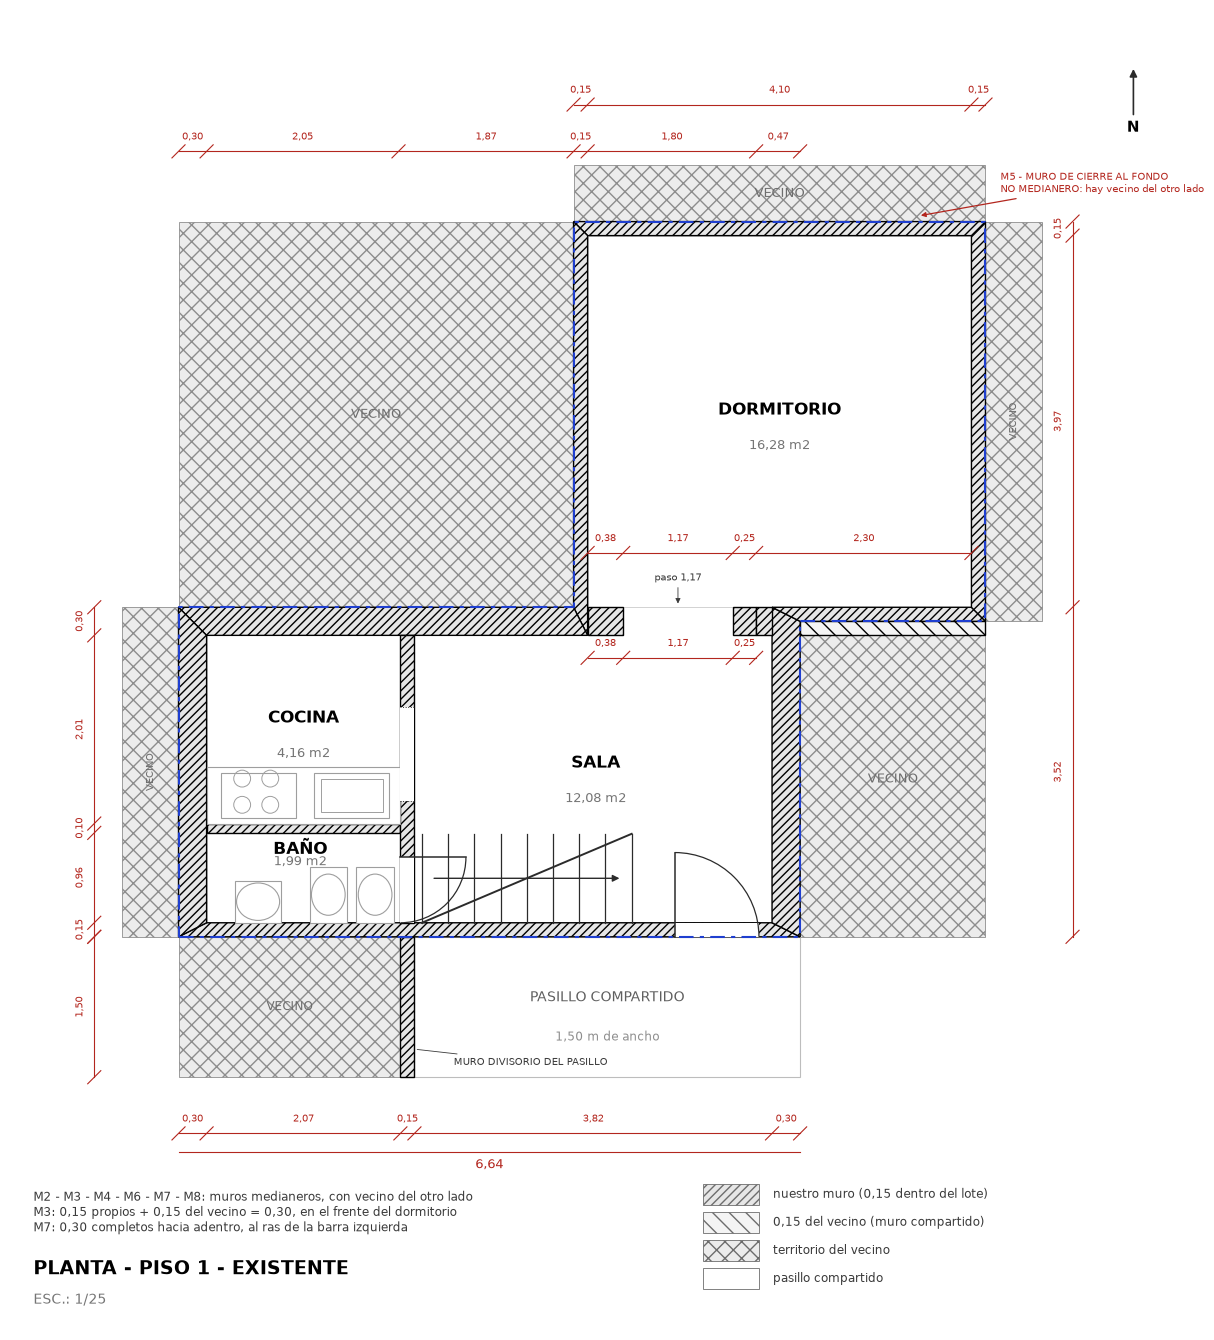

In [4]:
# 6. verificacion, reporte impreso y lamina

MUROS_PERIMETRALES = MUROS[:len(LIMITES_XY_M)]
MURO_PASILLO = next(muro for muro in MUROS if muro.id == 'MD')

AREA_LIMITES_M2 = area_poligono(LIMITES_XY_M)
AREA_INTERIOR_M2 = area_poligono(CARAS_INTERIORES_XY_M)
AREA_MUROS_M2 = sum(muro.area_m2 for muro in MUROS_PERIMETRALES)
AREA_TABIQUES_M2 = sum(area_poligono(poligono) for poligono in TABIQUES_XY_M.values())
AREA_UTIL_M2 = sum(area_poligono(poligono) for poligono in LOCALES_XY_M.values())
AREA_MURO_PASILLO_M2 = MURO_PASILLO.area_m2

# 1) el anillo de muros perimetrales no deja huecos ni material duplicado
assert abs((AREA_LIMITES_M2 - AREA_INTERIOR_M2) - AREA_MUROS_M2) < 1e-6, 'anillo de muros inconsistente'
# 2) los locales mas los tabiques cubren exactamente la cara interior
assert abs((AREA_UTIL_M2 + AREA_TABIQUES_M2) - AREA_INTERIOR_M2) < 1e-6, 'locales y tabiques no cierran'

# 3) sin solapes de material entre muros: se corta poligono contra poligono
SOLAPES = []
for i, muro_a in enumerate(MUROS):
    for muro_b in MUROS[i + 1:]:
        area_m2 = area_interseccion_convexos(muro_a.cuadro_xy, muro_b.cuadro_xy)
        if area_m2 > 1e-6:
            SOLAPES.append((muro_a.id, muro_b.id, round(area_m2, 4)))
assert not SOLAPES, f'solapes detectados: {SOLAPES}'

# 4) el lote y las dos muescas del vecino completan el rectangulo envolvente del territorio
AREA_ENVOLVENTE_M2 = X_BLOQUE_FONDO_DER_M * (Y_FONDO_M - Y_FACHADA_M)
AREA_MUESCAS_M2 = (area_poligono(VECINOS_XY_M['VECINO OESTE (muesca Z)'])
                   + area_poligono(VECINOS_XY_M['VECINO ESTE (muesca Z)']))
assert abs((AREA_LIMITES_M2 + AREA_MUESCAS_M2) - AREA_ENVOLVENTE_M2) < 1e-6, \
    'el lote no cierra con el rectangulo envolvente del territorio'

# 5) la franja del pasillo cierra: territorio del vecino mas muro divisorio mas pasillo
AREA_BANDA_PASILLO_M2 = area_poligono(PASILLO_BANDA_XY_M)
AREA_BANDA_REPARTIDA_M2 = (area_poligono(VECINO_EN_PASILLO_XY_M) + AREA_MURO_PASILLO_M2
                           + area_poligono(PASILLO_COMPARTIDO_XY_M))
assert abs(AREA_BANDA_REPARTIDA_M2 - AREA_BANDA_PASILLO_M2) < 1e-6, 'la franja del pasillo no cierra'

# 6) el muro divisorio del pasillo queda fuera del lote
assert max(p[1] for p in MURO_PASILLO.cuadro_xy) <= Y_FACHADA_M + 1e-9, 'el muro divisorio invade el lote'

# 7) el espesor compartido de M3 y M7 queda completo (0.30) y siempre del lado del vecino
COMPARTIDOS = [muro for muro in MUROS if muro.espesor_vecino_m > 0]
assert {muro.id for muro in COMPARTIDOS} == {'M3'}, \
    f'muros con espesor del vecino: {[muro.id for muro in COMPARTIDOS]}'
for muro in COMPARTIDOS:
    assert abs(muro.espesor_total_m - 0.30) < 1e-9, f'{muro.id}: espesor total {muro.espesor_total_m:.2f}'
    assert not punto_dentro_poligono(centroide_poligono(muro.cuadro_afuera_xy), LIMITES_XY_M), \
        f'{muro.id}: el espesor del vecino quedo dentro del lote'
AREA_VECINO_MUROS_M2 = sum(muro.largo_m * muro.espesor_vecino_m for muro in COMPARTIDOS)

# 8) todo tramo del contorno declara su vecino y la unica excepcion a medianera es M5
assert all(muro.lindero for muro in MUROS_PERIMETRALES), 'hay tramos sin lindero declarado'
NO_MEDIANERAS = [muro.id for muro in MUROS_PERIMETRALES
                 if not muro.es_medianera and muro.tipo != 'fachada']
assert NO_MEDIANERAS == ['M5'], f'la unica excepcion a las medianeras debe ser M5: {NO_MEDIANERAS}'

print('--- verificacion ---')
print('cubierta a caras exteriores:', f'{AREA_LIMITES_M2:.2f} m2')
print('interior entre caras:', f'{AREA_INTERIOR_M2:.2f} m2')
print('muros perimetrales:', f'{AREA_MUROS_M2:.2f} m2')
print('tabiques:', f'{AREA_TABIQUES_M2:.2f} m2')
print('superficie util:', f'{AREA_UTIL_M2:.2f} m2')
print('solapes:', len(SOLAPES))
print('muro divisorio del pasillo:', f'{AREA_MURO_PASILLO_M2:.2f} m2', '(fuera del lote)')
print('barras del paso: T4', f'{BARRA_PASO_IZQ_LARGO_M:.2f} x {ESP_BARRA_PASO_M:.2f}',
      '| T3', f'{BARRA_PASO_DER_LARGO_M:.2f} x {ESP_BARRA_PASO_M:.2f}',
      '| arranque del frente', f'{ARRANQUE_FRENTE_DORMITORIO_M:.2f}',
      '| paso libre', f'{PASO_LIBRE_M:.2f} m')
print('recuadro del dormitorio:', f'{ANCHO_DORMITORIO_M:.2f} m',
      f'({BARRA_PASO_IZQ_LARGO_M:.2f} + {PASO_LIBRE_M:.2f} + {BARRA_PASO_DER_LARGO_M:.2f}'
      f' + {RESTO_DERECHO_DORMITORIO_M:.2f})')
print('espesor del vecino dibujado:', f'{AREA_VECINO_MUROS_M2:.2f} m2',
      '(M3, fuera del lote: no suma a nuestra superficie)')

print()
print('--- muros ---')
print(f'{"id":<4}{"tipo":<52}{"esp":>6}{"vec":>6}{"total":>7}{"luz":>7}')
for muro in MUROS:
    print(f'{muro.id:<4}{muro.tipo:<52}{muro.espesor_m:>6.2f}{muro.espesor_vecino_m:>6.2f}'
          f'{muro.espesor_total_m:>7.2f}{muro.luz_util_m:>7.2f}')

print()
print('--- linderos ---')
print(f'{"id":<4}{"medianera":<11}{"fuera del lote":<16}{"lindero"}')
for muro in MUROS:
    if not muro.lindero:
        continue
    print(f'{muro.id:<4}{("si" if muro.es_medianera else "no"):<11}'
          f'{("si" if muro.fuera_del_lote else "no"):<16}{muro.lindero}')
print()
print('todos los linderos del contorno tienen vecino;')
print('el unico muro de lindero que no es medianero es M5, al fondo del dormitorio.')

print()
print('--- locales ---')
MINIMOS_M2 = {'BAÑO': 2.50, 'COCINA': 5.00, 'SALA': 10.00, 'DORMITORIO': 8.00}
for nombre, poligono in LOCALES_XY_M.items():
    superficie_m2 = area_poligono(poligono)
    minimo_m2 = MINIMOS_M2[nombre]
    estado = 'cumple' if superficie_m2 >= minimo_m2 else 'no cumple (existente)'
    print(f'{nombre:<12} util: {superficie_m2:>5.2f} m2 | minimo: {minimo_m2:.2f} | {estado}')

print()
print('--- vanos ---')
for vano in VANOS:
    print(f'{vano.id:<4}{vano.id_muro:<4}{vano.tipo:<10} desde: {vano.distancia_m:>5.2f} | '
          f'ancho: {vano.ancho_m:.2f} | antepecho: {vano.antepecho_m:.2f} | alto: {vano.altura_libre_m:.2f}')

# lamina: vecinos, limites, locales, muros con hatch, aberturas, escalera, artefactos y cotas
COLOR_COTA = '#b3261e'
COLOR_LIMITE = '#1f3fd0'
COLOR_MURO = '#e6e6e6'
COLOR_TRAZO = '#2b2b2b'
COLOR_VECINO = '#ececec'
COLOR_VECINO_TRAZO = '#8d8d8d'
COLOR_MURO_VECINO = '#f4f4f4'

fig, ax = plt.subplots(figsize=(12.5, 13.5))
ax.set_aspect('equal')
ax.axis('off')

# territorio del vecino: las dos muescas de la Z y una franja por cada lindero exterior
for poligono in VECINOS_XY_M.values():
    ax.add_patch(Polygon(poligono, closed=True, facecolor=COLOR_VECINO,
                         edgecolor=COLOR_VECINO_TRAZO, lw=0.6, hatch='xx', zorder=1))
    centro_x = sum(p[0] for p in poligono) / len(poligono)
    centro_y = sum(p[1] for p in poligono) / len(poligono)
    ancho_m = max(p[0] for p in poligono) - min(p[0] for p in poligono)
    vertical = ancho_m < 1.00
    ax.text(centro_x, centro_y, 'VECINO', ha='center', va='center',
            rotation=90 if vertical else 0, fontsize=7.0 if vertical else 9.5,
            color='#6d6d6d', zorder=2)

# pasillo compartido: sector del vecino, muro divisorio y pasillo
ax.add_patch(Polygon(VECINO_EN_PASILLO_XY_M, closed=True, facecolor=COLOR_VECINO,
                     edgecolor=COLOR_VECINO_TRAZO, lw=0.6, hatch='xx', zorder=1))
ax.add_patch(Polygon(PASILLO_COMPARTIDO_XY_M, closed=True, facecolor='white',
                     edgecolor='#bdbdbd', lw=0.8, zorder=1))
Y_CENTRO_PASILLO_M = (Y_FACHADA_M + Y_PASILLO_FONDO_M) / 2
ax.text((X_LIMITE_IZQ_M + X_MURO_PASILLO_IZQ_M) / 2, Y_CENTRO_PASILLO_M, 'VECINO',
        ha='center', va='center', fontsize=8.5, color='#6d6d6d', zorder=2)
ax.text((X_MURO_PASILLO_DER_M + X_BLOQUE_DELANTERO_DER_M) / 2, Y_FACHADA_M - 0.65,
        'PASILLO COMPARTIDO', ha='center', va='center', fontsize=10, color='#5f5f5f', zorder=2)
ax.text((X_MURO_PASILLO_DER_M + X_BLOQUE_DELANTERO_DER_M) / 2, Y_FACHADA_M - 1.07,
        '1,50 m de ancho', ha='center', va='center', fontsize=8.5, color='#8d8d8d', zorder=2)

# el bano tiene los sanitarios contra la fachada: su rotulo va en la franja libre
ROTULO_LOCAL_M = {
    'BAÑO': {'centro': (1.30, 0.90), 'nombre_dy': 0.05, 'area_dy': -0.10},
}

for nombre, poligono in LOCALES_XY_M.items():
    ax.add_patch(Polygon(poligono, closed=True, facecolor='white', edgecolor='#cfcfcf',
                         lw=0.6, zorder=2))
    ajuste = ROTULO_LOCAL_M.get(nombre, {})
    centro_x, centro_y = ajuste.get('centro', centroide_poligono(poligono))
    ax.text(centro_x, centro_y + ajuste.get('nombre_dy', 0.12), nombre, ha='center', va='center',
            fontsize=12, fontweight='bold', zorder=7)
    ax.text(centro_x, centro_y + ajuste.get('area_dy', -0.26),
            f'{area_poligono(poligono):.2f} m2'.replace('.', ','),
            ha='center', va='center', fontsize=9, color='#757575', zorder=7)

for muro in MUROS:
    if muro.espesor_vecino_m > 0:
        ax.add_patch(Polygon(muro.cuadro_afuera_xy, closed=True, facecolor=COLOR_MURO_VECINO,
                             edgecolor='black', lw=1.0, hatch='\\\\', zorder=3.5))
    ax.add_patch(Polygon(muro.cuadro_xy, closed=True, facecolor=COLOR_MURO, edgecolor='black',
                         lw=1.0, hatch='////', zorder=4))

for _, poligono in ARTEFACTOS_M:
    ax.add_patch(Polygon(poligono, closed=True, facecolor='white', edgecolor='#9e9e9e',
                         lw=0.8, zorder=5))
for centro_x in (0.68, 0.98):
    for centro_y in (1.41, 1.69):
        ax.add_patch(Circle((centro_x, centro_y), 0.09, facecolor='none', edgecolor='#9e9e9e',
                            lw=0.7, zorder=6))
ax.add_patch(Polygon(rectangulo_xy(1.52, 1.33, 2.18, 1.69), closed=True, facecolor='none',
                     edgecolor='#9e9e9e', lw=0.7, zorder=6))
ax.add_patch(Ellipse((0.85, 0.375), 0.46, 0.40, facecolor='white', edgecolor='#9e9e9e',
                     lw=0.8, zorder=6))
ax.add_patch(Ellipse((1.60, 0.45), 0.36, 0.44, facecolor='white', edgecolor='#9e9e9e',
                     lw=0.8, zorder=6))
ax.add_patch(Ellipse((2.10, 0.45), 0.36, 0.44, facecolor='white', edgecolor='#9e9e9e',
                     lw=0.8, zorder=6))

ESC = ESCALERA_M
for i in range(ESC['pasos'] + 1):
    x = ESC['x_ini'] + i * ESC['huella']
    ax.plot([x, x], [ESC['y_ini'], ESC['y_ini'] + ESC['ancho']], color=COLOR_TRAZO, lw=0.9, zorder=6)
x_fin = ESC['x_ini'] + ESC['pasos'] * ESC['huella']
y_medio = ESC['y_ini'] + ESC['ancho'] / 2
ax.annotate('', xy=(x_fin - 0.10, y_medio), xytext=(ESC['x_ini'] + 0.10, y_medio),
            arrowprops=dict(arrowstyle='-|>', color=COLOR_TRAZO, lw=1.0), zorder=7)
ax.plot([ESC['x_ini'], x_fin], [ESC['y_ini'], ESC['y_ini'] + ESC['ancho']],
        color=COLOR_TRAZO, lw=1.4, zorder=7)

for vano in VANOS:
    muro = {m.id: m for m in MUROS}[vano.id_muro]
    x0, y0 = muro.cara_1_xy[0]
    ux, uy = muro.direccion_xy
    d0, d1 = vano.distancia_m, vano.distancia_m + vano.ancho_m
    a0 = (x0 + ux * d0, y0 + uy * d0)
    a1 = (x0 + ux * d1, y0 + uy * d1)
    b0 = muro.punto_cara_2(d0)
    b1 = muro.punto_cara_2(d1)
    ax.add_patch(Polygon([a0, a1, b1, b0], closed=True, facecolor='white',
                         edgecolor='none', zorder=6))
    if vano.tipo == 'ventana':
        ax.plot([a0[0], a1[0]], [a0[1], a1[1]], color=COLOR_TRAZO, lw=0.9, zorder=7)
        ax.plot([b0[0], b1[0]], [b0[1], b1[1]], color=COLOR_TRAZO, lw=0.9, zorder=7)
    elif vano.tipo == 'puerta':
        radio_m = vano.ancho_m
        angulo = math.degrees(math.atan2(uy, ux))
        ax.add_patch(Arc(a0, 2 * radio_m, 2 * radio_m, angle=0.0, theta1=angulo,
                         theta2=angulo + 90, color=COLOR_TRAZO, lw=0.9, zorder=7))
        ax.plot([a0[0], a0[0] - uy * radio_m], [a0[1], a0[1] + ux * radio_m],
                color=COLOR_TRAZO, lw=1.1, zorder=7)
    else:
        ax.plot([a0[0], b0[0]], [a0[1], b0[1]], color=COLOR_TRAZO, lw=0.7, ls=':', zorder=7)
        ax.plot([a1[0], b1[0]], [a1[1], b1[1]], color=COLOR_TRAZO, lw=0.7, ls=':', zorder=7)

xs = [p[0] for p in LIMITES_XY_M] + [LIMITES_XY_M[0][0]]
ys = [p[1] for p in LIMITES_XY_M] + [LIMITES_XY_M[0][1]]
ax.plot(xs, ys, color=COLOR_LIMITE, lw=1.5, ls=(0, (7, 3, 2, 3)), zorder=8)

dibujar_cadena(ax, 0.00, 'x', CADENAS_COTAS_M['fachada (X)'][0], Y_PASILLO_FONDO_M - 0.60)
dibujar_cadena(ax, 0.00, 'x', CADENAS_COTAS_M['union de bloques (X)'][0], Y_FONDO_M + 0.75)
dibujar_cadena(ax, X_BLOQUE_FONDO_IZQ_M, 'x', CADENAS_COTAS_M['fondo del bloque (X)'][0],
               Y_FONDO_M + 1.25)
dibujar_cadena(ax, Y_FACHADA_M, 'y', CADENAS_COTAS_M['columna izquierda (Y)'][0], -0.90)
dibujar_cadena(ax, Y_FACHADA_M, 'y', CADENAS_COTAS_M['lateral derecho (Y)'][0],
               X_BLOQUE_FONDO_DER_M + 0.93)
dibujar_cadena(ax, X_BARRA_PASO_IZQ_DESDE_M, 'x',
               CADENAS_COTAS_M['paso sala-dormitorio (X)'][0], 2.98)
# recuadro del dormitorio: 0,38 + 1,17 + 0,25 + 2,30 = 4,10 entre caras interiores
dibujar_cadena(ax, X_BARRA_PASO_IZQ_DESDE_M, 'x',
               CADENAS_COTAS_M['recuadro del dormitorio (X)'][0], Y_BLOQUE_DELANTERO_FONDO_M + 0.58)
CENTRO_PASO_M = (X_BARRA_PASO_IZQ_HASTA_M + X_BARRA_PASO_DER_DESDE_M) / 2
ax.annotate(f'paso {PASO_LIBRE_M:.2f}'.replace('.', ','),
            xy=(CENTRO_PASO_M, Y_BARRA_PASO_FONDO_M + 0.01),
            xytext=(CENTRO_PASO_M, Y_BARRA_PASO_FONDO_M + 0.26),
            ha='center', va='bottom', fontsize=7.5, color='#3a3a3a', zorder=9,
            bbox=dict(boxstyle='round,pad=0.18', facecolor='white', edgecolor='none', alpha=0.85),
            arrowprops=dict(arrowstyle='-|>', color='#3a3a3a', lw=0.6))
dibujar_cadena(ax, Y_PASILLO_FONDO_M, 'y', [ANCHO_PASILLO_COMPARTIDO_M], -0.90)

ax.plot([0.00, X_BLOQUE_DELANTERO_DER_M],
        [Y_PASILLO_FONDO_M - 0.80, Y_PASILLO_FONDO_M - 0.80], color=COLOR_COTA, lw=0.8, zorder=9)
ax.text(X_BLOQUE_DELANTERO_DER_M / 2, Y_PASILLO_FONDO_M - 0.87, '6,64', ha='center', va='top',
        fontsize=9, color=COLOR_COTA, zorder=9)

# rotulos de lindero: la excepcion del fondo y el muro que parte el pasillo
ax.annotate('M5 - MURO DE CIERRE AL FONDO\nNO MEDIANERO: hay vecino del otro lado',
            xy=(7.90, Y_FONDO_M + 0.06), xytext=(8.78, Y_FONDO_M + 0.28), ha='left', va='bottom',
            fontsize=7.0, color=COLOR_COTA, zorder=9,
            arrowprops=dict(arrowstyle='-|>', color=COLOR_COTA, lw=0.9))
ax.annotate('MURO DIVISORIO DEL PASILLO', xy=(X_MURO_PASILLO_DER_M, Y_PASILLO_FONDO_M + 0.30),
            xytext=(X_MURO_PASILLO_DER_M + 0.42, Y_PASILLO_FONDO_M + 0.16), ha='left', va='center',
            fontsize=7.5, color='#3a3a3a', zorder=9,
            arrowprops=dict(arrowstyle='-', color='#3a3a3a', lw=0.6))
ax.text(-1.55, -2.70, 'M2 - M3 - M4 - M6 - M7 - M8: muros medianeros, con vecino del otro lado\n'
                      'M3: 0,15 propios + 0,15 del vecino = 0,30, en el frente del dormitorio\n'
                      'M7: 0,30 completos hacia adentro, al ras de la barra izquierda',
        ha='left', va='top', fontsize=8.5, color='#3a3a3a', zorder=9)

# leyenda de la lamina
LEYENDA = [('////', COLOR_MURO, 'nuestro muro (0,15 dentro del lote)'),
           ('\\\\', COLOR_MURO_VECINO, '0,15 del vecino (muro compartido)'),
           ('xx', COLOR_VECINO, 'territorio del vecino'),
           (None, 'white', 'pasillo compartido')]
for i, (hatch, color, texto) in enumerate(LEYENDA):
    y = -2.75 - i * 0.30
    ax.add_patch(Rectangle((5.60, y - 0.11), 0.60, 0.22, facecolor=color, edgecolor='#6d6d6d',
                           lw=0.6, hatch=hatch, zorder=9))
    ax.text(6.35, y, texto, ha='left', va='center', fontsize=8.5, color='#3a3a3a', zorder=9)

ax.annotate('N', xy=(10.20, 9.30), xytext=(10.20, 8.60), ha='center', fontsize=11,
            fontweight='bold', arrowprops=dict(arrowstyle='-|>', color=COLOR_TRAZO, lw=1.2))
ax.text(-1.55, -3.55, 'PLANTA - PISO 1 - EXISTENTE', fontsize=14, fontweight='bold',
        ha='left', va='center')
ax.text(-1.55, -3.88, 'ESC.: 1/25', fontsize=10, color='#757575', ha='left', va='center')

ax.set_xlim(-1.80, 10.60)
ax.set_ylim(-4.20, 9.90)
plt.tight_layout()
plt.show()


## Criterios de medicion y pendientes

- **Superficie util**: poligono medido entre caras interiores. No incluye tabiques.
- **Superficie cubierta**: poligono de limites de propiedad, o sea caras exteriores. Se informa aparte, nunca sumada a la util.
- **Medianeras**: el plano dibuja nuestro muro ocupando todo el espesor dentro del lote (`0.30` en las laterales del bloque delantero y `0.15` en el bloque de fondo). El muro compartido real es el doble: lo que se dibuja es nuestra mitad, el vecino aporta la otra.
- **Muros de 0.30 alineados con las barras**: `M3` se dibuja con `0.30` (`0.15` propios + `0.15` del vecino, con la linea de propiedad en el medio) y cierra el frente del dormitorio al ras del arranque `T5`. `M7` tambien se dibuja con `0.30`, pero completo adentro del lote (`3.22-3.52`), al ras de la barra izquierda: ese espesor crece hacia la sala y la cocina.
- **Bloque delantero**: mide `3.52` entre caras exteriores, igual que el relevamiento. La columna izquierda cierra en `0.15` de fachada + `0.96` de baño + `0.10` de tabique humedo + `2.01` de cocina + `0.30` de M7, con la fachada sobre el limite de propiedad.
- **Excepcion al criterio de medianera**: el muro `M5`, al fondo del dormitorio sobre `Y = 7.64`, es muro propio de cierre. No es medianero, pero **si hay vecino** del otro lado. Es el unico lindero del contorno que no es medianera; `M1` es fachada al pasillo compartido y el resto (`M2`, `M3`, `M4`, `M6`, `M7`, `M8`) son medianeras con vecino.
- **Vanos**: relativos al muro. La validacion falla si el vano no entra en la luz util o si cae sobre una medianera; la condicion se controla con la bandera `es_medianera` del muro, no con el texto del tipo.
- **Vertices reflex**: el perimetro tiene dos, en `(6.64, 3.37)` y `(4.22, 3.52)`. El corte de los lados desplazados consecutivos da el vertice correcto tambien ahi.
- **Pasillo compartido**: franja de `1.50` delante de la fachada, fuera del lote, partida por el muro `MD` (alineado con `T2`). El sector oeste es territorio del vecino, el sector este es el pasillo. Ninguno de los dos suma superficie.
- **Barras del paso sala-dormitorio**: `T4` (izquierda) mide `0.38` y `T3` (derecha) `0.25`, ambas de `0.30` de espesor. La cara norte coincide con el frente del dormitorio (`Y = 3.52`) y el espesor crece hacia la sala, para no alterar la profundidad util del dormitorio (`3.97`, cadena del plano). El **frente del dormitorio arranca en la cara este de `T3`** (`X = 6.17`) y corre hasta la cara interior de `M4` (`X = 8.47`): el recuadro del dormitorio entre caras interiores cierra en `4.10 = 0.38 + 1.17 + 0.25 + 2.30`, y los `2.30` del resto derecho son `0.17` de arranque del muro sobre la cara interior de `M2` mas `2.13` del frente propio de `M3`. El arranque `T5` tiene los mismos `0.30` de las barras, asi que la barra derecha y el muro no forman escalon.

**Pendientes a ajustar sobre el primer render**

1. El tabique humedo bano-cocina quedo en `0.10` y la columna izquierda cierra en `3.52` (`0.15` + `0.96` + `0.10` + `2.01` + `0.30`): el espesor de M7 no obliga a resignar superficie de bano ni de cocina.
2. La escalera y las aberturas se ubicaron siguiendo los peldaños y los arcos del plano. Confirmar posiciones sobre el dibujo.
3. La cocina no tiene ventilacion directa porque el bano ocupa la fachada en la columna izquierda: condicion existente.
4. Bano (`1.99 m2`) y cocina (`4.16 m2`) estan por debajo de los minimos normativos: se reportan como existentes, sin romper el script.
5. El muro divisorio del pasillo se toma de `0.15` alineado con `T2`. Si fuera lindero de lote, seria `0.15` propio mas `0.15` del vecino, como el resto de las medianeras.
6. La fachada frente al bano es un muro ciego: no hay ventana y el bano queda sin ventilacion directa. Condicion existente. Los sanitarios van contra ese muro y el pasaje libre queda del lado del tabique bano/cocina.
7. Con M7 en `0.30` hacia adentro el cuello entre sala y dormitorio pasa a tener `0.30` de profundidad y la sala queda en `12.08`: su borde norte se corre a `3.22` y el paso, con `1.17`, le devuelve parte de esa superficie. El baño (`1.99`), la cocina (`4.16`) y el dormitorio (`16.28`) conservan sus m2 exactos.
